# Land-Cover Segmentation (LandCover.ai): Baseline + U-Net | OLD split

**Split used:** the *official* LandCover.ai split (train 7,470 / val 1,602 / test 1,602 patches), prepared by the data teammate.
This split is made at **patch level**, so patches of the same source image appear in train, val and test (data leakage, see section 2).
We keep it to compare with the leakage-free split (notebook "new_split").

**Models:** Random Forest baseline and a U-Net trained from scratch, each with 3 random seeds.

**Contents:** data, training, validation, test, experiments, plots (training curves, mIoU, per-class IoU, precision/recall, confusion matrix, example predictions) and the saved demo package.

**How to run**
1. Settings -> Accelerator -> **GPU**. Add the teammate's notebook `shazahanybakr/dataset` as an input.
2. Keep `SMOKE = True` and click **Run All**. This is a quick test of the whole pipeline (a few minutes).
3. Set `SMOKE = False` and use **Save Version -> Save & Run All (Commit)** for the real run (about 1 hour).

## 0) Task, hypotheses and course requirements

**Task:** semantic segmentation of aerial images. Input: an RGB patch (512x512 px, resized to 256x256). Output: a class for every pixel
(Background, Buildings, Woodlands, Water, Roads). Dataset: LandCover.ai (public). Main metric: mIoU (mean IoU over the 5 classes).

**Hypotheses**
- **H1:** a U-Net (a CNN that sees spatial context) beats the pixel-wise Random Forest baseline, mainly on Buildings and Roads.
- **H2:** a class-weighted loss improves the IoU of the rare classes (Buildings, Roads) compared with an unweighted loss.
- **H3:** data augmentation improves the validation mIoU.
- **H4:** the official patch-level split (with leakage) gives higher scores than the leakage-free tile-level split.

**Where each requirement of the course PDF is covered**

| # | Requirement | Where / who |
|---|-------------|-------------|
| 1 | Problem definition and 3+ hypotheses | this section (full text in the report) |
| 2 | Public dataset and leakage-free split | LandCover.ai. Leakage check of the official split + tile-level split (notebook "new_split") |
| 3 | Baseline | Random Forest on pixel features |
| 4 | Classic, modern and advanced model | Classic = U-Net (here). Modern and advanced = teammates (SegFormer, DeepLabV3+) |
| 5 | Train it ourselves + write a component | U-Net from scratch (`unet_model.py`) and the metrics file `seg_eval.py` |
| 6 | Fair comparison, 3 seeds | same split, preprocessing, image size and epochs for all models; seeds 0, 1, 42 |
| 7 | Experiments | hyperparameter (learning rate) and data strategy (class weights, augmentation) in the "Experiments" section. Pretrained vs scratch = teammates' pretrained model |
| 8 | Ablation | removing the class weights / the augmentation ("Experiments" section) |
| 9 | Evaluation | mIoU, Dice, per-class IoU / precision / recall, mean and SD over seeds |
| 10 | Error analysis | confusion matrix, precision / recall, example predictions (written analysis goes in the report) |
| 11 | Computational cost | "Computational cost" section |
| 12 | Live demo | `demo_package` saved at the end (model + prediction code + Streamlit example) |
| 13 | No shortcuts | no external AI API; the U-Net has no pretrained weights; the dataset is credited |
| 14 | Individual understanding | viva |

## 1) Settings and imports
All settings are in one block. `SMOKE = True` runs everything on tiny subsets with 1 epoch, only to check that there are no errors.
The image size (256) is the same for every model, so comparisons are fair.

In [1]:
import os, sys, glob, json, time, random
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader, Subset

sys.path.append("/kaggle/input/notebooks/shazahanybakr/dataset")   # teammate's dataset.py
sys.path.append("/kaggle/working")                                   # our seg_eval.py (created below)
from dataset import get_dataloaders, get_transforms, CLASS_NAMES, CLASS_WEIGHTS_SMOOTH

# ===================== SETTINGS =====================
SMOKE = False          # True = quick test on tiny subsets (minutes) | False = real run
SPLIT_NAME = "old_split"   # which split this notebook uses (do not change)
IMG_SIZE = 256        # must be the same for ALL models and ALL team members
BATCH_SIZE = 16
EPOCHS = 10
LR = 1e-3
SEEDS = [0, 1, 42]
RUN_EXPERIMENTS = False   # hyperparameter / data-strategy / ablation runs (1 seed each, about 1 hour extra)
# ====================================================

DATA_ROOT = "/kaggle/input/notebooks/shazahanybakr/dataset/processed_data"
OUT_DIR = "/kaggle/working/results"
os.makedirs(OUT_DIR, exist_ok=True)
RUN_NAME = SPLIT_NAME + ("_SMOKE" if SMOKE else "")      # used in output file names (smoke files never overwrite real ones)

NUM_CLASSES = len(CLASS_NAMES)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_SEEDS = [0] if SMOKE else SEEDS          # smoke test uses one seed and one epoch
RUN_EPOCHS = 1 if SMOKE else EPOCHS

def set_seed(seed):
    """Make a run reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

print("Device:", DEVICE, "| SMOKE:", SMOKE, "| split:", SPLIT_NAME, "| image size:", IMG_SIZE)
print("Classes:", CLASS_NAMES)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Settings -> Accelerator -> GPU")

Device: cuda | SMOKE: False | split: old_split | image size: 256
Classes: ['Background', 'Buildings', 'Woodlands', 'Water', 'Roads']


## 2) Leakage check on the official split
Every source image (tile) was cut into many patches of 512x512. A patch name looks like `M-33-20-D-c-4-2_17`
(tile name + patch number). If the same tile name appears in train and in test, the model is tested on places that are
right next to places it trained on. This is **data leakage**: the scores look better than they really are.

In [2]:
tiles = {}
for s in ["train", "val", "test"]:
    names = os.listdir(f"{DATA_ROOT}/{s}/images")
    tiles[s] = {n.rsplit("_", 1)[0] for n in names}      # "M-33-20-D-c-4-2_17.jpg" -> tile "M-33-20-D-c-4-2"
    print(f"{s}: {len(names)} patches from {len(tiles[s])} source tiles")

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = tiles[a] & tiles[b]
    print(f"{a} & {b}: {len(shared)} shared tiles", "-> LEAKAGE" if shared else "-> OK")

train: 7470 patches from 41 source tiles
val: 1602 patches from 41 source tiles
test: 1602 patches from 41 source tiles
train & val: 41 shared tiles -> LEAKAGE
train & test: 41 shared tiles -> LEAKAGE
val & test: 41 shared tiles -> LEAKAGE


## 3) Data loaders
`get_loaders()` returns the train / val / test loaders of the official split.
Each image is resized to `IMG_SIZE`, normalized with ImageNet mean/std, and the training images are augmented
(flips, 90-degree rotations, small brightness/contrast changes). Val and test images are never augmented.

In [3]:
def shrink(loader, n, train=False):
    """Random small subset of a loader (used only for the SMOKE test)."""
    ds = loader.dataset
    idx = np.random.default_rng(0).choice(len(ds), min(n, len(ds)), replace=False).tolist()
    return DataLoader(Subset(ds, idx), batch_size=BATCH_SIZE, shuffle=train, num_workers=2, drop_last=train)

def get_loaders(use_augmentation=True):
    """Train / val / test loaders of the OFFICIAL split (patch-level), built by the data teammate's dataset.py."""
    tr, va, te = get_dataloaders(data_root=DATA_ROOT, batch_size=BATCH_SIZE, img_size=IMG_SIZE,
                                 use_augmentation=use_augmentation, num_workers=2)
    if SMOKE:
        tr, va, te = shrink(tr, 160, train=True), shrink(va, 64), shrink(te, 64)
    return tr, va, te

tr, va, te = get_loaders(True)
print(f"train {len(tr.dataset)} | val {len(va.dataset)} | test {len(te.dataset)}")
imgs, masks = next(iter(tr))
print("batch:", imgs.shape, masks.shape, masks.dtype, "| classes in batch:", torch.unique(masks).tolist())

train 7470 | val 1602 | test 1602
batch: torch.Size([16, 3, 256, 256]) torch.Size([16, 256, 256]) torch.int64 | classes in batch: [0, 1, 2, 3, 4]


## 4) Evaluation file (`seg_eval.py`), written by us and shared with the team
Accuracy is misleading here (Background + Woodlands are about 91% of the pixels), so we report **IoU** per class and the mean **mIoU**.
IoU = overlap between prediction and truth divided by their union. All metrics are computed from a confusion matrix.

In [4]:
%%writefile /kaggle/working/seg_eval.py
import numpy as np
import torch

CLASS_NAMES = ["Background", "Buildings", "Woodlands", "Water", "Roads"]
NUM_CLASSES = len(CLASS_NAMES)


def confusion_matrix(pred, target, n_classes=NUM_CLASSES):
    """Rows = true class, columns = predicted class."""
    pred = pred.reshape(-1)
    target = target.reshape(-1)
    valid = (target >= 0) & (target < n_classes)
    idx = n_classes * target[valid].long() + pred[valid].long()
    return torch.bincount(idx, minlength=n_classes ** 2).reshape(n_classes, n_classes)


def metrics_from_cm(cm):
    """Segmentation metrics from a confusion matrix (classes absent everywhere give NaN and are ignored in the mean)."""
    cm = cm.double()
    tp = cm.diag()
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    eps = 1e-12

    iou_den = tp + fp + fn
    dice_den = 2 * tp + fp + fn
    iou = torch.where(iou_den > 0, tp / (iou_den + eps), torch.full_like(tp, float("nan")))
    dice = torch.where(dice_den > 0, 2 * tp / (dice_den + eps), torch.full_like(tp, float("nan")))
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    return {
        "mIoU": float(np.nanmean(iou.numpy())),
        "mDice": float(np.nanmean(dice.numpy())),
        "pixel_acc": float(tp.sum() / (cm.sum() + eps)),
        "per_class_IoU": iou.tolist(),
        "per_class_Dice": dice.tolist(),
        "per_class_precision": precision.tolist(),
        "per_class_recall": recall.tolist(),
    }


@torch.no_grad()
def evaluate_model(model, loader, device, use_amp=True):
    """Shared evaluation loop for all deep learning models."""
    model.eval()
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.autocast(device_type="cuda", enabled=use_amp and device == "cuda"):
            logits = model(imgs)
        cm += confusion_matrix(logits.argmax(dim=1), masks)
    return metrics_from_cm(cm.cpu()), cm.cpu()


def print_report(m, title=""):
    print(f"=== {title} ===")
    print(f"mIoU: {m['mIoU']:.4f} | mDice: {m['mDice']:.4f} | pixel acc: {m['pixel_acc']:.4f}")
    print(f"{'class':<12}{'IoU':>8}{'Dice':>8}{'Prec':>8}{'Recall':>8}")
    for i, name in enumerate(CLASS_NAMES):
        print(f"{name:<12}{m['per_class_IoU'][i]:>8.4f}{m['per_class_Dice'][i]:>8.4f}"
              f"{m['per_class_precision'][i]:>8.4f}{m['per_class_recall'][i]:>8.4f}")

Writing /kaggle/working/seg_eval.py


In [5]:
from seg_eval import confusion_matrix, metrics_from_cm, evaluate_model, print_report

# Sanity test: a perfect prediction must give mIoU = 1.0
target = torch.randint(0, NUM_CLASSES, (2, 64, 64))
m = metrics_from_cm(confusion_matrix(target, target))
assert abs(m["mIoU"] - 1.0) < 1e-6, "mIoU should be 1.0 for a perfect prediction"
print("seg_eval sanity test passed")

seg_eval sanity test passed


## 5) Baseline: Random Forest on pixel features
A classical machine-learning reference. We sample pixels from training images, and for every pixel we compute 8 features:
its color (3), the local average color (3), the local texture (1) and a wider-area brightness (1). A Random Forest then
predicts the class of each pixel. Extra pixels of every class are sampled so that rare classes are not missed.

In [6]:
from sklearn.ensemble import RandomForestClassifier
import joblib

NUM_FEATURES = 8

@torch.no_grad()
def pixel_features(imgs):
    """imgs: (B,3,H,W) normalized -> (B,8,H,W): RGB + 7x7 mean RGB + 7x7 gray std + 15x15 gray mean."""
    r, g, b = imgs[:, 0:1], imgs[:, 1:2], imgs[:, 2:3]
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    mean7 = F.avg_pool2d(imgs, 7, stride=1, padding=3, count_include_pad=False)
    g_mean = F.avg_pool2d(gray, 7, stride=1, padding=3, count_include_pad=False)
    g_sq = F.avg_pool2d(gray ** 2, 7, stride=1, padding=3, count_include_pad=False)
    g_std = (g_sq - g_mean ** 2).clamp(min=0).sqrt()               # local texture
    g_mean15 = F.avg_pool2d(gray, 15, stride=1, padding=7, count_include_pad=False)   # wider context
    return torch.cat([imgs, mean7, g_std, g_mean15], dim=1)

def sample_training_pixels(loader, n_images, uniform_per_img, per_class_per_img, seed):
    """Per image: random pixels + a few pixels of every class (so rare classes appear in the sample)."""
    rng = np.random.default_rng(seed)
    X_list, y_list, seen = [], [], 0
    for imgs, masks in loader:
        feats = pixel_features(imgs)
        for b in range(imgs.shape[0]):
            f = feats[b].reshape(NUM_FEATURES, -1).T.numpy()
            m = masks[b].reshape(-1).numpy()
            idx = [rng.choice(len(m), uniform_per_img, replace=False)]
            for c in range(NUM_CLASSES):
                cls_idx = np.flatnonzero(m == c)
                if len(cls_idx) > 0:
                    idx.append(rng.choice(cls_idx, min(per_class_per_img, len(cls_idx)), replace=False))
            idx = np.concatenate(idx)
            X_list.append(f[idx])
            y_list.append(m[idx])
        seen += imgs.shape[0]
        if seen >= n_images:
            break
    return np.concatenate(X_list), np.concatenate(y_list)

def evaluate_rf(clf, loader, stride):
    """Evaluate on a regular grid of pixels (every `stride`-th pixel) of ALL images, to keep it fast."""
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    for imgs, masks in loader:
        feats = pixel_features(imgs)[:, :, ::stride, ::stride]
        m = masks[:, ::stride, ::stride]
        X = feats.permute(0, 2, 3, 1).reshape(-1, NUM_FEATURES).numpy()
        pred = clf.predict(X)
        cm += confusion_matrix(torch.from_numpy(pred), m.reshape(-1))
    return metrics_from_cm(cm), cm

In [7]:
N_IMAGES = 40 if SMOKE else 1000     # training images used for pixel sampling
UNIFORM_PER_IMG = 150                # random pixels per image
PER_CLASS_PER_IMG = 50               # extra pixels per class per image
RF_STRIDE = 4                        # evaluation grid (256 / 4 = 64 x 64 pixels per image)

rf_train, rf_val, _ = get_loaders(use_augmentation=False)   # no augmentation for the baseline
rf_results = {"model": "RandomForest_pixel", "split": SPLIT_NAME, "seeds": {}}
rf_clfs = {}

for seed in RUN_SEEDS:
    set_seed(seed)
    t0 = time.time()
    X, y = sample_training_pixels(rf_train, N_IMAGES, UNIFORM_PER_IMG, PER_CLASS_PER_IMG, seed)
    clf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=seed)
    clf.fit(X, y)
    train_time = time.time() - t0

    t1 = time.time()
    val_m, _ = evaluate_rf(clf, rf_val, RF_STRIDE)
    infer_time = (time.time() - t1) / len(rf_val.dataset)
    print_report(val_m, f"Baseline RF | {SPLIT_NAME} | val | seed {seed}")

    rf_results["seeds"][seed] = {"val": val_m, "train_time_s": train_time, "infer_s_per_img": infer_time}
    rf_clfs[seed] = clf

# model size and number of tree nodes (last seed)
joblib.dump(clf, f"{OUT_DIR}/rf_{RUN_NAME}.joblib", compress=3)
rf_results["model_size_MB"] = os.path.getsize(f"{OUT_DIR}/rf_{RUN_NAME}.joblib") / 1e6
rf_results["total_tree_nodes"] = int(sum(e.tree_.node_count for e in clf.estimators_))

miou = np.array([rf_results["seeds"][s]["val"]["mIoU"] for s in RUN_SEEDS])
print(f"\nRF val mIoU: {miou.mean():.4f}" + (f" +- {miou.std(ddof=1):.4f}" if len(miou) > 1 else ""))

with open(f"{OUT_DIR}/rf_{RUN_NAME}_results.json", "w") as f:
    json.dump(rf_results, f, indent=2)

=== Baseline RF | old_split | val | seed 0 ===
mIoU: 0.4618 | mDice: 0.6005 | pixel acc: 0.8083
class            IoU    Dice    Prec  Recall
Background    0.7426  0.8523  0.8601  0.8446
Buildings     0.2306  0.3748  0.4073  0.3471
Woodlands     0.6558  0.7921  0.7646  0.8217
Water         0.4773  0.6462  0.8112  0.5370
Roads         0.2026  0.3370  0.2764  0.4316
=== Baseline RF | old_split | val | seed 1 ===
mIoU: 0.4699 | mDice: 0.6089 | pixel acc: 0.8107
class            IoU    Dice    Prec  Recall
Background    0.7424  0.8522  0.8692  0.8358
Buildings     0.2383  0.3848  0.5390  0.2992
Woodlands     0.6608  0.7958  0.7581  0.8374
Water         0.4974  0.6643  0.7597  0.5903
Roads         0.2104  0.3476  0.2917  0.4301
=== Baseline RF | old_split | val | seed 42 ===
mIoU: 0.4527 | mDice: 0.5902 | pixel acc: 0.8060
class            IoU    Dice    Prec  Recall
Background    0.7417  0.8517  0.8584  0.8451
Buildings     0.2134  0.3517  0.3795  0.3277
Woodlands     0.6545  0.7912  0.7649

## 6) U-Net from scratch (classic CNN)
The encoder (4 stages of convolutions + pooling) learns *what* is in the image, and the decoder (4 stages of upsampling)
recovers *where* it is. Skip connections copy detailed features from the encoder to the decoder. No pretrained weights.

In [8]:
%%writefile /kaggle/working/unet_model.py
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    """(Conv 3x3 -> BatchNorm -> ReLU) x 2"""
    def __init__(self, c_in, c_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_ch=3, n_classes=5, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]            # 32, 64, 128, 256, 512 channels
        # encoder (going down)
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.bottleneck = DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        # decoder (going up): upsample, then concatenate the skip connection, then DoubleConv
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, 1)                        # one score per class for every pixel

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

Writing /kaggle/working/unet_model.py


In [9]:
from unet_model import UNet

# quick shape check
_m = UNet(n_classes=NUM_CLASSES)
print("output:", tuple(_m(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape),
      "| parameters: %.2fM" % (sum(p.numel() for p in _m.parameters()) / 1e6))
del _m

output: (1, 5, 256, 256) | parameters: 7.76M


## 7) Training function
- Loss: cross-entropy with **class weights** (rare classes such as Buildings get a higher weight, so the model does not ignore them).
- Optimizer: Adam with a cosine learning-rate schedule. Mixed precision on GPU for speed.
- After each epoch we compute the **validation mIoU** and keep the best epoch. The test set is never used here.

In [10]:
def time_inference(model, loader, n_batches=5):
    """Average seconds per image on the GPU (after warm-up)."""
    model.eval()
    imgs, _ = next(iter(loader))
    imgs = imgs.to(DEVICE)
    use_amp = DEVICE == "cuda"
    with torch.no_grad(), autocast(device_type="cuda", enabled=use_amp):
        for _ in range(2):
            model(imgs)
        if use_amp: torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(n_batches):
            model(imgs)
        if use_amp: torch.cuda.synchronize()
    return (time.time() - t0) / (n_batches * imgs.size(0))


def train_unet(seed, train_loader, val_loader, epochs, lr, tag, use_class_weights=True):
    set_seed(seed)
    model = UNet(n_classes=NUM_CLASSES).to(DEVICE)
    weights = torch.tensor(CLASS_WEIGHTS_SMOOTH, dtype=torch.float32, device=DEVICE) if use_class_weights else None
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    use_amp = DEVICE == "cuda"                      # mixed precision: faster training, less memory
    scaler = GradScaler("cuda", enabled=use_amp)
    ckpt_path = f"{OUT_DIR}/{tag}_seed{seed}.pt"
    if use_amp:
        torch.cuda.reset_peak_memory_stats()

    best_miou, best_metrics, history, t_start = -1.0, None, [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, n_batches, t0 = 0.0, 0, time.time()
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast(device_type="cuda", enabled=use_amp):
                loss = loss_fn(model(imgs), masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item()
            n_batches += 1
        scheduler.step()

        val_m, _ = evaluate_model(model, val_loader, DEVICE, use_amp=use_amp)
        history.append({"epoch": epoch, "train_loss": total_loss / n_batches, "val_mIoU": val_m["mIoU"]})
        flag = ""
        if val_m["mIoU"] > best_miou:                       # keep the best epoch (by VAL mIoU)
            best_miou, best_metrics = val_m["mIoU"], val_m
            torch.save(model.state_dict(), ckpt_path)
            flag = "  <- best"
        print(f"[seed {seed}] epoch {epoch:>2}/{epochs} | loss {total_loss / n_batches:.4f} | "
              f"val mIoU {val_m['mIoU']:.4f} | {time.time() - t0:.0f}s{flag}")

    train_time = time.time() - t_start
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))        # reload the best checkpoint
    return {"val": best_metrics, "history": history, "train_time_s": train_time,
            "infer_s_per_img": time_inference(model, val_loader),
            "n_params": sum(p.numel() for p in model.parameters()),
            "size_MB": os.path.getsize(ckpt_path) / 1e6,
            "peak_mem_GB": (torch.cuda.max_memory_allocated() / 1e9) if use_amp else None,
            "hardware": torch.cuda.get_device_name(0) if use_amp else "cpu",
            "ckpt": ckpt_path}

## 8) Train the U-Net with 3 seeds

In [11]:
unet_train, unet_val, _ = get_loaders(use_augmentation=True)
unet_results = {"model": "UNet_scratch", "split": SPLIT_NAME, "img_size": IMG_SIZE,
                "epochs": RUN_EPOCHS, "lr": LR, "seeds": {}}

for seed in RUN_SEEDS:
    unet_results["seeds"][seed] = train_unet(seed, unet_train, unet_val, RUN_EPOCHS, LR, tag=f"unet_{RUN_NAME}")
    print_report(unet_results["seeds"][seed]["val"], f"U-Net | {SPLIT_NAME} | val | seed {seed} (best epoch)")

miou = np.array([unet_results["seeds"][s]["val"]["mIoU"] for s in RUN_SEEDS])
print(f"\nU-Net val mIoU: {miou.mean():.4f}" + (f" +- {miou.std(ddof=1):.4f}" if len(miou) > 1 else ""))

with open(f"{OUT_DIR}/unet_{RUN_NAME}_results.json", "w") as f:
    json.dump(unet_results, f, indent=2)

[seed 0] epoch  1/10 | loss 0.8881 | val mIoU 0.4105 | 223s  <- best
[seed 0] epoch  2/10 | loss 0.6902 | val mIoU 0.4555 | 97s  <- best
[seed 0] epoch  3/10 | loss 0.6124 | val mIoU 0.5144 | 97s  <- best
[seed 0] epoch  4/10 | loss 0.5532 | val mIoU 0.5542 | 97s  <- best
[seed 0] epoch  5/10 | loss 0.5166 | val mIoU 0.6071 | 97s  <- best
[seed 0] epoch  6/10 | loss 0.4678 | val mIoU 0.6037 | 97s
[seed 0] epoch  7/10 | loss 0.4462 | val mIoU 0.6136 | 97s  <- best
[seed 0] epoch  8/10 | loss 0.4034 | val mIoU 0.6214 | 97s  <- best
[seed 0] epoch  9/10 | loss 0.3889 | val mIoU 0.6205 | 97s
[seed 0] epoch 10/10 | loss 0.3774 | val mIoU 0.6458 | 97s  <- best
=== U-Net | old_split | val | seed 0 (best epoch) ===
mIoU: 0.6458 | mDice: 0.7608 | pixel acc: 0.9025
class            IoU    Dice    Prec  Recall
Background    0.8552  0.9220  0.9526  0.8933
Buildings     0.4023  0.5738  0.4380  0.8316
Woodlands     0.8290  0.9065  0.8800  0.9347
Water         0.7949  0.8857  0.8681  0.9040
Roads    

## 9) Comparison on the validation set: Random Forest vs U-Net

In [12]:
def mean_sd(res, class_idx=None):
    vals = np.array([res["seeds"][s]["val"]["mIoU"] if class_idx is None
                     else res["seeds"][s]["val"]["per_class_IoU"][class_idx] for s in RUN_SEEDS])
    sd = vals.std(ddof=1) if len(vals) > 1 else 0.0
    return f"{vals.mean():.3f} +- {sd:.3f}"

print(f"Split: {SPLIT_NAME} | image size: {IMG_SIZE} | seeds: {RUN_SEEDS}")
print(f"{'Model':<26}{'mIoU':>16}" + "".join(f"{n:>16}" for n in CLASS_NAMES))
for name, res in [("RandomForest (baseline)", rf_results), ("U-Net (scratch)", unet_results)]:
    print(f"{name:<26}{mean_sd(res):>16}" + "".join(f"{mean_sd(res, i):>16}" for i in range(NUM_CLASSES)))

Split: old_split | image size: 256 | seeds: [0, 1, 42]
Model                                 mIoU      Background       Buildings       Woodlands           Water           Roads
RandomForest (baseline)     0.461 +- 0.009  0.742 +- 0.000  0.227 +- 0.013  0.657 +- 0.003  0.477 +- 0.020  0.203 +- 0.007
U-Net (scratch)             0.639 +- 0.009  0.850 +- 0.005  0.411 +- 0.011  0.830 +- 0.002  0.760 +- 0.037  0.344 +- 0.008


## 10) Computational cost (report Table 7)

In [13]:
u = [unet_results["seeds"][s] for s in RUN_SEEDS]
r = [rf_results["seeds"][s] for s in RUN_SEEDS]
print(f"U-Net : params {u[0]['n_params'] / 1e6:.2f}M | size {u[0]['size_MB']:.1f} MB | "
      f"train {np.mean([x['train_time_s'] for x in u]) / 60:.1f} min | "
      f"inference {np.mean([x['infer_s_per_img'] for x in u]) * 1000:.1f} ms/img | "
      f"peak GPU memory {u[0]['peak_mem_GB']} GB | {u[0]['hardware']}")
print(f"RF    : tree nodes {rf_results['total_tree_nodes']:,} | size {rf_results['model_size_MB']:.1f} MB | "
      f"train {np.mean([x['train_time_s'] for x in r]) / 60:.1f} min | "
      f"inference {np.mean([x['infer_s_per_img'] for x in r]) * 1000:.1f} ms/img (grid stride {RF_STRIDE}) | CPU")

U-Net : params 7.76M | size 31.1 MB | train 16.8 min | inference 3.3 ms/img | peak GPU memory 1.715255296 GB | Tesla T4
RF    : tree nodes 2,659,206 | size 69.7 MB | train 1.4 min | inference 70.1 ms/img (grid stride 4) | CPU


## 11) Experiments: hyperparameter study, data-strategy study and ablation
Every experiment changes **one thing** compared with the main U-Net (learning rate 1e-3, class weights, augmentation) and uses the same
split, image size, number of epochs and seed. They are evaluated on the **validation** set (the test set is not used here).
- Hyperparameter study: learning rate 3e-4 and 3e-3.
- Data-strategy study and ablation: training **without class weights** and training **without augmentation** (a component is removed and the effect is measured).

Controlled by `RUN_EXPERIMENTS` in the settings (about 1 hour extra on GPU; each run uses one seed).

In [14]:
# Same budget for every run: same split, image size, epochs and seed. Evaluated on the VALIDATION set only.
exp_results = {}
exp_seed = RUN_SEEDS[0]

if RUN_EXPERIMENTS:
    exp_train_aug, exp_val, _ = get_loaders(use_augmentation=True)
    exp_train_plain, _, _ = get_loaders(use_augmentation=False)
    experiments = [
        # (name, study, learning rate, class weights?, training loader)
        ("lr = 3e-4", "hyperparameter", 3e-4, True, exp_train_aug),
        ("lr = 3e-3", "hyperparameter", 3e-3, True, exp_train_aug),
        ("no class weights", "data strategy / ablation", LR, False, exp_train_aug),
        ("no augmentation", "data strategy / ablation", LR, True, exp_train_plain),
    ]
    if SMOKE:
        experiments = experiments[:2]          # smoke test only checks that the code runs
    for i, (name, study, lr_, use_w, loader_) in enumerate(experiments):
        out = train_unet(exp_seed, loader_, exp_val, RUN_EPOCHS, lr_, tag=f"exp{i}_{RUN_NAME}", use_class_weights=use_w)
        exp_results[name] = {"study": study, "val": out["val"]}
        print_report(out["val"], f"Experiment: {name} | val | seed {exp_seed}")
    with open(f"{OUT_DIR}/experiments_{RUN_NAME}.json", "w") as f:
        json.dump(exp_results, f, indent=2)
else:
    print("Experiments skipped (RUN_EXPERIMENTS = False).")

Experiments skipped (RUN_EXPERIMENTS = False).


In [15]:
import matplotlib.pyplot as plt

if exp_results:
    ref = unet_results["seeds"][exp_seed]["val"]          # main run (lr 1e-3, class weights, augmentation), same seed
    rows = [{"Study": "reference", "Setting": "main (lr 1e-3, class weights, augmentation)", "val mIoU": ref["mIoU"],
             "delta vs main": 0.0, "IoU Buildings": ref["per_class_IoU"][1], "IoU Roads": ref["per_class_IoU"][4]}]
    for name, r in exp_results.items():
        v = r["val"]
        rows.append({"Study": r["study"], "Setting": name, "val mIoU": v["mIoU"], "delta vs main": v["mIoU"] - ref["mIoU"],
                     "IoU Buildings": v["per_class_IoU"][1], "IoU Roads": v["per_class_IoU"][4]})
    exp_df = pd.DataFrame(rows).round(4)
    print(exp_df.to_string(index=False))
    exp_df.to_csv(f"{OUT_DIR}/experiments_{RUN_NAME}.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 3 + 0.5 * len(rows)))
    colors = ["#2b6cb0"] + ["#dd6b20"] * (len(rows) - 1)
    ax.barh([r["Setting"] for r in rows][::-1], [r["val mIoU"] for r in rows][::-1], color=colors[::-1])
    for y, r in enumerate(rows[::-1]):
        ax.text(r["val mIoU"] + 0.005, y, f"{r['val mIoU']:.3f}", va="center", fontsize=9)
    ax.set_xlabel("Validation mIoU (single seed)")
    ax.set_xlim(0, 1)
    ax.set_title(f"Hyperparameter, data-strategy and ablation experiments ({SPLIT_NAME})")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig7_experiments_{RUN_NAME}.png", dpi=150)
    plt.show()
else:
    print("No experiment results (RUN_EXPERIMENTS = False).")

No experiment results (RUN_EXPERIMENTS = False).


## 12) Final test (run once, at the very end)
Runs only when `SMOKE = False`. Both models are evaluated on the test set, using the checkpoints / classifiers selected on validation.

In [16]:
# The test set is used only here, once, after all models and settings are fixed.
_, _, test_loader = get_loaders(use_augmentation=False)
print("Test samples:", len(test_loader.dataset), "(SMOKE: tiny subset, numbers are meaningless)" if SMOKE else "")
final = {"split": SPLIT_NAME, "img_size": IMG_SIZE, "seeds": RUN_SEEDS, "rf": {}, "unet": {}}
test_cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)       # U-Net confusion matrix, summed over seeds

for seed in RUN_SEEDS:
    m_rf, _ = evaluate_rf(rf_clfs[seed], test_loader, RF_STRIDE)
    final["rf"][seed] = m_rf
    print_report(m_rf, f"RF | {SPLIT_NAME} | TEST | seed {seed}")

    model = UNet(n_classes=NUM_CLASSES).to(DEVICE)
    model.load_state_dict(torch.load(f"{OUT_DIR}/unet_{RUN_NAME}_seed{seed}.pt", map_location=DEVICE))
    m_un, cm_un = evaluate_model(model, test_loader, DEVICE, use_amp=(DEVICE == "cuda"))
    final["unet"][seed] = m_un
    test_cm += cm_un
    print_report(m_un, f"U-Net | {SPLIT_NAME} | TEST | seed {seed}")
    del model

print(f"\nFINAL TEST ({SPLIT_NAME}) - mIoU, mean +- SD over seeds")
for name in ["rf", "unet"]:
    v = np.array([final[name][s]["mIoU"] for s in RUN_SEEDS])
    pc = np.array([final[name][s]["per_class_IoU"] for s in RUN_SEEDS])
    sd = v.std(ddof=1) if len(v) > 1 else 0.0
    print(f"{name:<6} mIoU {v.mean():.4f} +- {sd:.4f}")
    for i, cname in enumerate(CLASS_NAMES):
        sdc = pc[:, i].std(ddof=1) if len(v) > 1 else 0.0
        print(f"       {cname:<12} IoU {pc[:, i].mean():.4f} +- {sdc:.4f}")

with open(f"{OUT_DIR}/final_test_{RUN_NAME}.json", "w") as f:
    json.dump(final, f, indent=2)

Test samples: 1602 
=== RF | old_split | TEST | seed 0 ===
mIoU: 0.4704 | mDice: 0.6090 | pixel acc: 0.8096
class            IoU    Dice    Prec  Recall
Background    0.7349  0.8472  0.8536  0.8409
Buildings     0.2308  0.3751  0.4131  0.3435
Woodlands     0.6768  0.8073  0.7821  0.8341
Water         0.4959  0.6630  0.8256  0.5539
Roads         0.2138  0.3522  0.3061  0.4148
=== U-Net | old_split | TEST | seed 0 ===
mIoU: 0.6385 | mDice: 0.7552 | pixel acc: 0.8982
class            IoU    Dice    Prec  Recall
Background    0.8436  0.9152  0.9494  0.8832
Buildings     0.3872  0.5583  0.4188  0.8371
Woodlands     0.8380  0.9118  0.8841  0.9413
Water         0.7741  0.8726  0.8531  0.8931
Roads         0.3495  0.5180  0.4570  0.5977
=== RF | old_split | TEST | seed 1 ===
mIoU: 0.4725 | mDice: 0.6108 | pixel acc: 0.8102
class            IoU    Dice    Prec  Recall
Background    0.7318  0.8451  0.8607  0.8301
Buildings     0.2294  0.3732  0.5398  0.2851
Woodlands     0.6812  0.8104  0.7766  

## 13) Results and plots
The figures below compare the two models (Random Forest and U-Net) and show where each one succeeds or fails.
All figures are also saved as PNG files in `results/`.

In [17]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# One colour per class (used for masks and legends)
PALETTE = np.array([[190, 190, 190],    # Background
                    [220, 50, 50],      # Buildings
                    [40, 150, 60],      # Woodlands
                    [50, 100, 220],     # Water
                    [240, 200, 40]],    # Roads
                   dtype=np.uint8)
CLASS_COLORS = PALETTE / 255.0

def msd(values):
    """Mean and standard deviation over seeds (SD = 0 when there is only one seed)."""
    v = np.array(values, dtype=float)
    sd = v.std(axis=0, ddof=1) if len(v) > 1 else np.zeros_like(v.mean(axis=0))
    return v.mean(axis=0), sd

def finish(fig_name):
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{fig_name}_{RUN_NAME}.png", dpi=150)
    plt.show()

# Numbers used by several plots
rf_val = [rf_results["seeds"][s]["val"]["mIoU"] for s in RUN_SEEDS]
un_val = [unet_results["seeds"][s]["val"]["mIoU"] for s in RUN_SEEDS]
rf_test = [final["rf"][s]["mIoU"] for s in RUN_SEEDS]
un_test = [final["unet"][s]["mIoU"] for s in RUN_SEEDS]

### Figure 1: U-Net training curves
The training loss should go down and the validation mIoU should go up. The dashed line is the Random Forest baseline on the same validation set.
If the validation curve is still rising at the last epoch, the model could improve with more training.

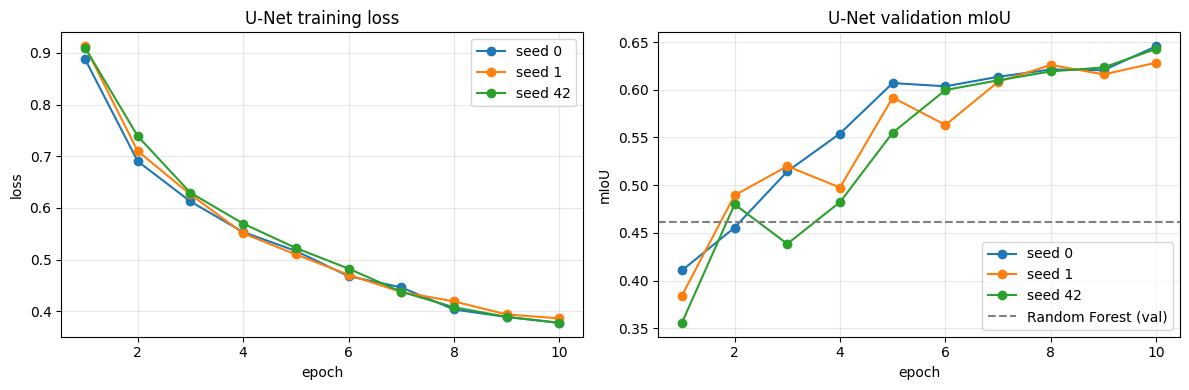

In [18]:
# Figure 1: U-Net training curves (is the model learning? is it still improving?)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in RUN_SEEDS:
    h = unet_results["seeds"][s]["history"]
    ep = [x["epoch"] for x in h]
    ax[0].plot(ep, [x["train_loss"] for x in h], marker="o", label=f"seed {s}")
    ax[1].plot(ep, [x["val_mIoU"] for x in h], marker="o", label=f"seed {s}")
ax[1].axhline(np.mean(rf_val), linestyle="--", color="gray", label="Random Forest (val)")
ax[0].set_title("U-Net training loss")
ax[0].set_ylabel("loss")
ax[1].set_title("U-Net validation mIoU")
ax[1].set_ylabel("mIoU")
for a in ax:
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
    a.legend()
finish("fig1_training_curves")

### Figure 2: overall mIoU (validation and test)
mIoU is the mean IoU over the 5 classes. Bars show the mean over the seeds and the error bars show the standard deviation.
A large gap between validation and test can mean that the validation set is easier or harder than the test set.

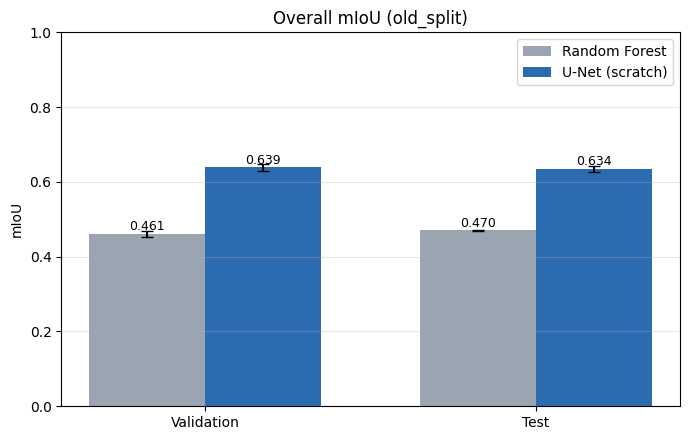

In [19]:
# Figure 2: overall mIoU of both models on validation and test (mean +- SD over seeds)
fig, ax = plt.subplots(figsize=(7, 4.5))
groups = ["Validation", "Test"]
x = np.arange(len(groups))
w = 0.35
for k, (name, vals, color) in enumerate([("Random Forest", [rf_val, rf_test], "#9aa5b1"),
                                         ("U-Net (scratch)", [un_val, un_test], "#2b6cb0")]):
    means = [np.mean(v) for v in vals]
    sds = [msd(v)[1] for v in vals]
    bars = ax.bar(x + (k - 0.5) * w, means, w, yerr=sds, capsize=4, label=name, color=color)
    for b, m in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, m + 0.01, f"{m:.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("mIoU")
ax.set_ylim(0, 1)
ax.set_title(f"Overall mIoU ({SPLIT_NAME})")
ax.grid(axis="y", alpha=0.3)
ax.legend()
finish("fig2_miou_val_test")

### Figure 3: IoU per class (test)
Shows which classes are easy (Background, Woodlands, Water) and which are hard. Buildings and Roads are rare and thin,
so they are usually the weakest classes.

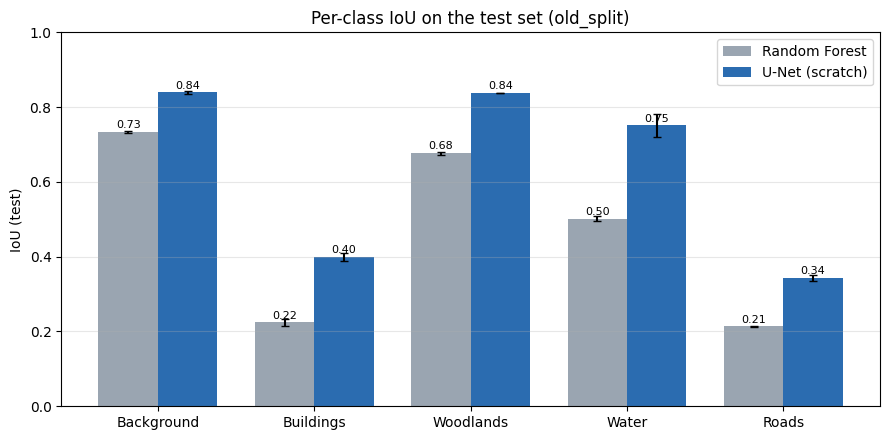

In [20]:
# Figure 3: IoU of every class on the test set (which classes are easy / hard?)
rf_pc = np.array([final["rf"][s]["per_class_IoU"] for s in RUN_SEEDS])
un_pc = np.array([final["unet"][s]["per_class_IoU"] for s in RUN_SEEDS])
x = np.arange(NUM_CLASSES)
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (name, arr, color) in enumerate([("Random Forest", rf_pc, "#9aa5b1"), ("U-Net (scratch)", un_pc, "#2b6cb0")]):
    mean, sd = msd(arr)
    bars = ax.bar(x + (k - 0.5) * w, mean, w, yerr=sd, capsize=3, label=name, color=color)
    for b, m in zip(bars, mean):
        ax.text(b.get_x() + b.get_width() / 2, m + 0.01, f"{m:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("IoU (test)")
ax.set_ylim(0, 1)
ax.set_title(f"Per-class IoU on the test set ({SPLIT_NAME})")
ax.grid(axis="y", alpha=0.3)
ax.legend()
finish("fig3_per_class_iou")

### Figure 4: U-Net precision and recall per class (test)
Precision = of the pixels predicted as a class, how many are right. Recall = of the real pixels of a class, how many were found.
High recall with low precision means the model over-predicts that class (this can come from the class weights, which push the
model to predict rare classes).

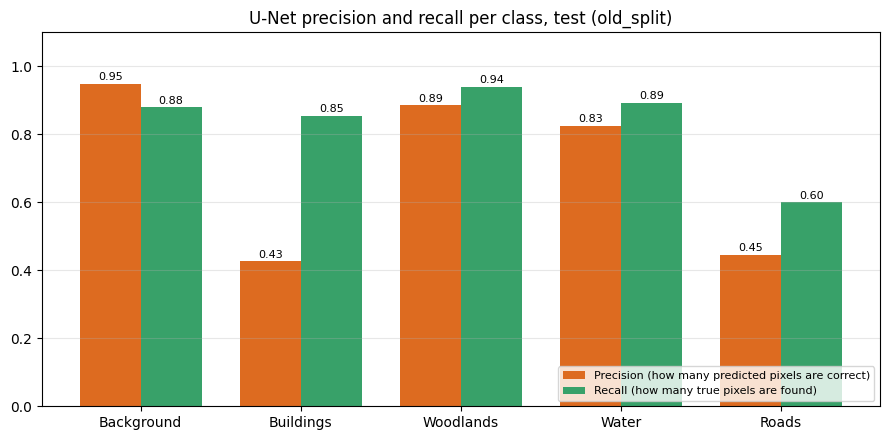

In [21]:
# Figure 4: U-Net precision vs recall per class (does it over-predict a class, or miss it?)
prec, _ = msd([final["unet"][s]["per_class_precision"] for s in RUN_SEEDS])
rec, _ = msd([final["unet"][s]["per_class_recall"] for s in RUN_SEEDS])
x = np.arange(NUM_CLASSES)
fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(x - 0.19, prec, 0.38, label="Precision (how many predicted pixels are correct)", color="#dd6b20")
b2 = ax.bar(x + 0.19, rec, 0.38, label="Recall (how many true pixels are found)", color="#38a169")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.1)
ax.set_title(f"U-Net precision and recall per class, test ({SPLIT_NAME})")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right", fontsize=8)
finish("fig4_precision_recall")

### Figure 5: U-Net confusion matrix (test)
Each row is the true class and each cell shows what share of its pixels was predicted as each class.
The diagonal is the share predicted correctly. Large off-diagonal values show which classes are confused with each other.

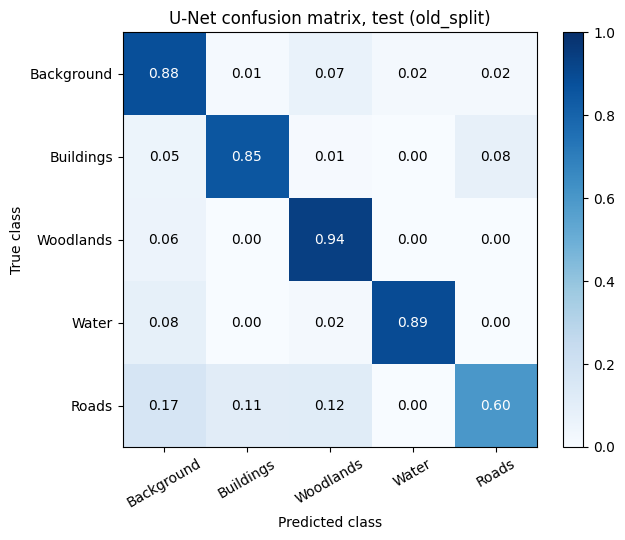

In [22]:
# Figure 5: U-Net confusion matrix on the test set (row = true class, column = predicted class)
cm = test_cm.numpy().astype(float)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=30)
ax.set_yticks(range(NUM_CLASSES))
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title(f"U-Net confusion matrix, test ({SPLIT_NAME})")
plt.colorbar(im, fraction=0.046)
finish("fig5_confusion_matrix")

### Figure 6: example predictions
Columns: input image, ground-truth mask, Random Forest prediction, U-Net prediction. The first rows show images with many
buildings and roads (hard cases); the last rows are random test images. The Random Forest looks at each pixel almost alone,
so its masks are noisy; the U-Net sees the whole context and gives cleaner regions.

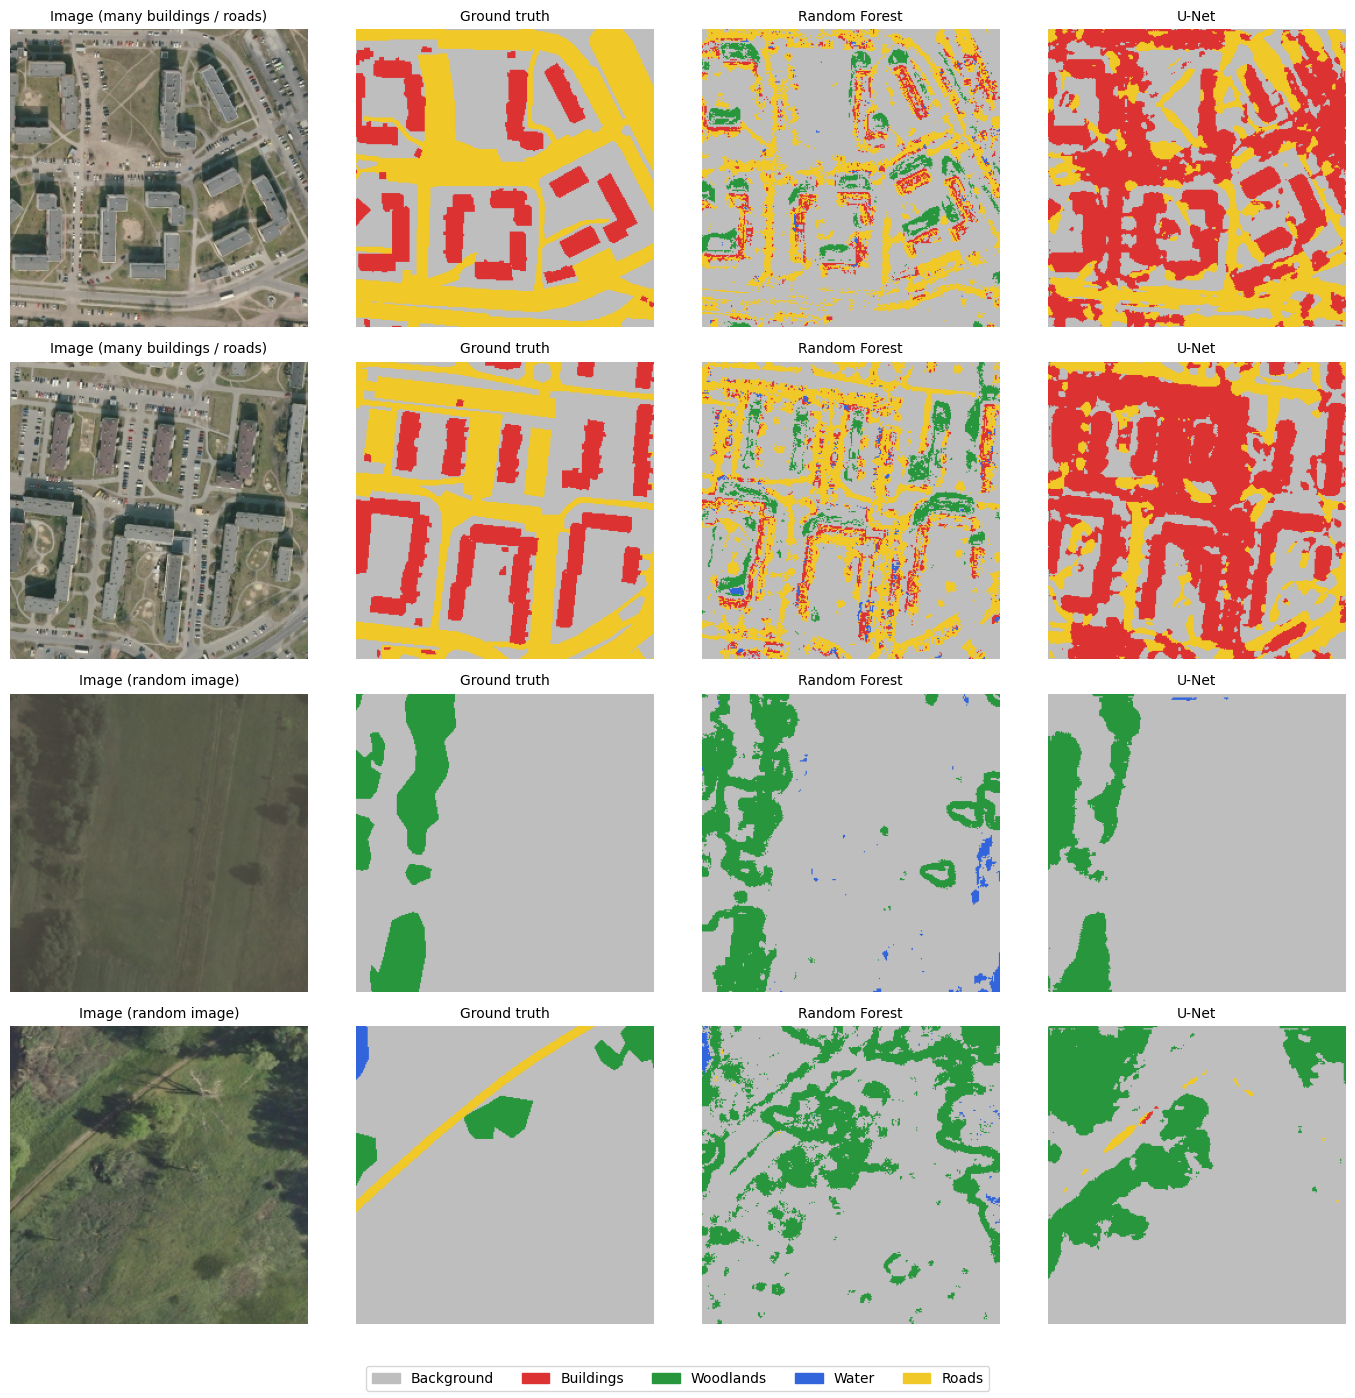

In [23]:
# Figure 6: example predictions on test images (image | ground truth | Random Forest | U-Net)
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def to_rgb(img):
    """Undo the ImageNet normalization so the image can be displayed."""
    return np.clip(img.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)

def pick_examples(loader, n_rare=2, n_random=2, seed=0):
    """Pick test images: the ones with the most Buildings + Roads pixels (hard cases) and some random ones."""
    hard = []
    for imgs, masks in loader:
        share = ((masks == 1) | (masks == 4)).float().mean(dim=(1, 2))
        for i in range(imgs.size(0)):
            hard.append((share[i].item(), imgs[i].clone(), masks[i].clone()))
        hard = sorted(hard, key=lambda t: -t[0])[:n_rare]
    ds = loader.dataset
    idx = np.random.default_rng(seed).choice(len(ds), n_random, replace=False)
    rand = [ds[int(i)] for i in idx]
    return [("many buildings / roads", im, mk) for _, im, mk in hard] + [("random image", im, mk) for im, mk in rand]

def rf_predict_image(clf, img):
    feats = pixel_features(img.unsqueeze(0))[0]                          # (8, H, W)
    X = feats.permute(1, 2, 0).reshape(-1, NUM_FEATURES).numpy()
    return clf.predict(X).reshape(img.shape[1], img.shape[2])

seed0 = RUN_SEEDS[0]
unet_model = UNet(n_classes=NUM_CLASSES).to(DEVICE)
unet_model.load_state_dict(torch.load(f"{OUT_DIR}/unet_{RUN_NAME}_seed{seed0}.pt", map_location=DEVICE))
unet_model.eval()

examples = pick_examples(test_loader)
fig, axes = plt.subplots(len(examples), 4, figsize=(14, 3.5 * len(examples)))
for r, (kind, img, mask) in enumerate(examples):
    with torch.no_grad():
        pred_unet = unet_model(img.unsqueeze(0).to(DEVICE)).argmax(1)[0].cpu().numpy()
    pred_rf = rf_predict_image(rf_clfs[seed0], img)
    panels = [(to_rgb(img), f"Image ({kind})"), (PALETTE[mask.numpy()], "Ground truth"),
              (PALETTE[pred_rf], "Random Forest"), (PALETTE[pred_unet], "U-Net")]
    for c, (pic, title) in enumerate(panels):
        axes[r, c].imshow(pic)
        axes[r, c].set_title(title, fontsize=10)
        axes[r, c].axis("off")
fig.legend(handles=[Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i]) for i in range(NUM_CLASSES)],
           loc="lower center", ncol=NUM_CLASSES)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f"{OUT_DIR}/fig6_predictions_{RUN_NAME}.png", dpi=150)
plt.show()

### Summary table and verdict
The final table gives validation and test mIoU and the test IoU of every class, and prints which model is best.

In [24]:
# Final summary table and verdict
def summary_row(name, val_list, test_dict):
    tm, tsd = msd([test_dict[s]["mIoU"] for s in RUN_SEEDS])
    pc, _ = msd([test_dict[s]["per_class_IoU"] for s in RUN_SEEDS])
    row = {"Model": name, "Val mIoU": f"{np.mean(val_list):.3f}", "Test mIoU": f"{tm:.3f} +- {tsd:.3f}"}
    row.update({f"IoU {c}": round(float(v), 3) for c, v in zip(CLASS_NAMES, pc)})
    return row

summary_df = pd.DataFrame([summary_row("Random Forest", rf_val, final["rf"]),
                           summary_row("U-Net (scratch)", un_val, final["unet"])])
print(summary_df.to_string(index=False))
summary_df.to_csv(f"{OUT_DIR}/summary_{RUN_NAME}.csv", index=False)

best = "U-Net (scratch)" if np.mean(un_test) > np.mean(rf_test) else "Random Forest"
gain = np.mean(un_test) - np.mean(rf_test)
print(f"\nBest model on the test set ({SPLIT_NAME}): {best} | U-Net - RF = {gain:+.3f} mIoU")

          Model Val mIoU      Test mIoU  IoU Background  IoU Buildings  IoU Woodlands  IoU Water  IoU Roads
  Random Forest    0.461 0.470 +- 0.002           0.734          0.225          0.677      0.502      0.214
U-Net (scratch)    0.639 0.634 +- 0.008           0.840          0.399          0.838      0.751      0.344

Best model on the test set (old_split): U-Net (scratch) | U-Net - RF = +0.164 mIoU


## 14) Evidence for the hypotheses
The numbers of this run for each hypothesis. A single-seed experiment is compared with the seed-to-seed noise of the main runs,
so small differences are reported as "not conclusive". The final verdict is written in the report.

In [25]:
# Evidence for the hypotheses (numbers from this run). The final verdict is written in the report.
noise = float(np.std(un_val, ddof=1)) if len(un_val) > 1 else 0.0
print(f"Seed noise = SD of the U-Net validation mIoU over seeds = {noise:.3f}")
print("(a difference smaller than this noise is not conclusive)\n")

rf_pc_mean = np.mean([final["rf"][s]["per_class_IoU"] for s in RUN_SEEDS], axis=0)
un_pc_mean = np.mean([final["unet"][s]["per_class_IoU"] for s in RUN_SEEDS], axis=0)

print("H1: U-Net beats the pixel-wise Random Forest, mainly on Buildings and Roads")
print(f"    test mIoU : U-Net {np.mean(un_test):.3f} vs RF {np.mean(rf_test):.3f}")
print(f"    Buildings : U-Net {un_pc_mean[1]:.3f} vs RF {rf_pc_mean[1]:.3f} | Roads: U-Net {un_pc_mean[4]:.3f} vs RF {rf_pc_mean[4]:.3f}")
h1 = np.mean(un_test) > np.mean(rf_test) and un_pc_mean[1] > rf_pc_mean[1] and un_pc_mean[4] > rf_pc_mean[4]
print("    ->", "supported" if h1 else "not (fully) supported")

if exp_results:
    ref = unet_results["seeds"][exp_seed]["val"]
    if "no class weights" in exp_results:
        nw = exp_results["no class weights"]["val"]
        rare_w, rare_n = np.mean([ref["per_class_IoU"][1], ref["per_class_IoU"][4]]), np.mean([nw["per_class_IoU"][1], nw["per_class_IoU"][4]])
        print("\nH2: class weights improve the IoU of the rare classes (Buildings, Roads)")
        print(f"    mean IoU of Buildings + Roads: with weights {rare_w:.3f} vs without {rare_n:.3f} (val, one seed)")
        print("    ->", "supported" if rare_w > rare_n else "not supported")
    if "no augmentation" in exp_results:
        na = exp_results["no augmentation"]["val"]
        d = ref["mIoU"] - na["mIoU"]
        print("\nH3: data augmentation improves validation mIoU")
        print(f"    with augmentation {ref['mIoU']:.3f} vs without {na['mIoU']:.3f} (difference {d:+.3f})")
        print("    ->", "supported" if d > noise else "not conclusive (difference within seed noise)")
else:
    print("\nH2 and H3 need the experiments (set RUN_EXPERIMENTS = True).")

print("\nH4: the official patch-level split (leakage) gives higher scores than the tile-level split")
print("    -> see the notebook 'landcover_compare_old_vs_new' (needs both runs).")

Seed noise = SD of the U-Net validation mIoU over seeds = 0.009
(a difference smaller than this noise is not conclusive)

H1: U-Net beats the pixel-wise Random Forest, mainly on Buildings and Roads
    test mIoU : U-Net 0.634 vs RF 0.470
    Buildings : U-Net 0.399 vs RF 0.225 | Roads: U-Net 0.344 vs RF 0.214
    -> supported

H2 and H3 need the experiments (set RUN_EXPERIMENTS = True).

H4: the official patch-level split (leakage) gives higher scores than the tile-level split
    -> see the notebook 'landcover_compare_old_vs_new' (needs both runs).


## 15) Save the trained model for the demo
Creates the folder `demo_package` (and a zip) with the best U-Net weights, the model code, a config file and the prediction code, plus an
example Streamlit app. The person who builds the demo only needs this zip: download it from the **Output** tab of the committed version.
The last cell tests the package by predicting one real test image the way the demo will do it.

In [26]:
import shutil

DEMO_DIR = "/kaggle/working/demo_package"
os.makedirs(DEMO_DIR, exist_ok=True)

# 1) The best U-Net (highest validation mIoU among the seeds)
best_seed = max(RUN_SEEDS, key=lambda s: unet_results["seeds"][s]["val"]["mIoU"])
shutil.copy(f"{OUT_DIR}/unet_{RUN_NAME}_seed{best_seed}.pt", f"{DEMO_DIR}/unet_best.pt")

# 2) The model code (the demo must use exactly the same architecture)
shutil.copy("/kaggle/working/unet_model.py", f"{DEMO_DIR}/unet_model.py")

# 3) Everything the demo needs to know about the model
config = {
    "model": "U-Net (from scratch)",
    "split": SPLIT_NAME,
    "best_seed": int(best_seed),
    "class_names": CLASS_NAMES,
    "palette": [[190, 190, 190], [220, 50, 50], [40, 150, 60], [50, 100, 220], [240, 200, 40]],
    "img_size": IMG_SIZE,            # the network input size
    "patch_size": 512,               # training patches are 512x512 pixels and are resized to img_size
    "mean": [0.485, 0.456, 0.406],   # ImageNet normalization
    "std": [0.229, 0.224, 0.225],
    "val_mIoU": float(unet_results["seeds"][best_seed]["val"]["mIoU"]),
    "test_mIoU_mean_over_seeds": float(np.mean(un_test)),
}
with open(f"{DEMO_DIR}/config.json", "w") as f:
    json.dump(config, f, indent=2)
print("Saved best checkpoint (seed", best_seed, ") and config.json in", DEMO_DIR)

Saved best checkpoint (seed 0 ) and config.json in /kaggle/working/demo_package


In [27]:
%%writefile /kaggle/working/demo_package/predict_utils.py
"""Helpers for the demo: load the U-Net, predict a mask for any aerial image, colour it, count the classes."""
import json
import os

import cv2
import numpy as np
import torch

from unet_model import UNet

HERE = os.path.dirname(os.path.abspath(__file__))


def load_config():
    with open(os.path.join(HERE, "config.json")) as f:
        return json.load(f)


def load_model(weights_path=None, device="cpu"):
    cfg = load_config()
    model = UNet(n_classes=len(cfg["class_names"]))
    model.load_state_dict(torch.load(weights_path or os.path.join(HERE, "unet_best.pt"), map_location=device))
    return model.to(device).eval()


@torch.no_grad()
def predict_mask(model, image_rgb, device="cpu"):
    """image_rgb: uint8 array (H, W, 3). Returns a uint8 mask (H, W) with the class id of every pixel.
    The image is cut into 512x512 tiles; every tile is resized to the network size, exactly like in training."""
    cfg = load_config()
    img_size, tile = cfg["img_size"], cfg["patch_size"]
    mean = np.array(cfg["mean"], dtype=np.float32)
    std = np.array(cfg["std"], dtype=np.float32)

    h, w = image_rgb.shape[:2]
    padded = cv2.copyMakeBorder(image_rgb, 0, (-h) % tile, 0, (-w) % tile, cv2.BORDER_REPLICATE)
    out = np.zeros(padded.shape[:2], dtype=np.uint8)
    for y in range(0, padded.shape[0], tile):
        for x in range(0, padded.shape[1], tile):
            patch = cv2.resize(padded[y:y + tile, x:x + tile], (img_size, img_size), interpolation=cv2.INTER_LINEAR)
            tensor = ((patch.astype(np.float32) / 255.0 - mean) / std).transpose(2, 0, 1)
            logits = model(torch.from_numpy(tensor).unsqueeze(0).to(device))
            pred = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
            out[y:y + tile, x:x + tile] = cv2.resize(pred, (tile, tile), interpolation=cv2.INTER_NEAREST)
    return out[:h, :w]


def colorize(mask):
    """Class-id mask -> RGB image."""
    return np.array(load_config()["palette"], dtype=np.uint8)[mask]


def overlay(image_rgb, mask, alpha=0.45):
    """Mask drawn on top of the image."""
    return (image_rgb * (1 - alpha) + colorize(mask) * alpha).astype(np.uint8)


def class_percentages(mask):
    """Share (%) of the pixels of every class."""
    names = load_config()["class_names"]
    counts = np.bincount(mask.reshape(-1), minlength=len(names))
    return {n: float(c) / mask.size * 100 for n, c in zip(names, counts)}

Writing /kaggle/working/demo_package/predict_utils.py


In [28]:
%%writefile /kaggle/working/demo_package/streamlit_app.py
"""Example Streamlit demo. Run:  streamlit run streamlit_app.py"""
import numpy as np
import streamlit as st
from PIL import Image

from predict_utils import class_percentages, colorize, load_config, load_model, overlay, predict_mask

st.set_page_config(page_title="Land-cover segmentation", layout="wide")
st.title("Land-cover segmentation from aerial images")
st.write("Upload an aerial image. A U-Net trained from scratch on LandCover.ai colours every pixel as "
         "Background, Buildings, Woodlands, Water or Roads.")

cfg = load_config()


@st.cache_resource
def get_model():
    return load_model()


with st.sidebar:
    st.header("Legend")
    for name, color in zip(cfg["class_names"], cfg["palette"]):
        st.markdown(f"<span style='color: rgb({color[0]},{color[1]},{color[2]}); font-size: 22px'>&#9632;</span> {name}",
                    unsafe_allow_html=True)
    st.caption(f"Model: {cfg['model']} | split: {cfg['split']} | validation mIoU: {cfg['val_mIoU']:.3f}")

uploaded = st.file_uploader("Aerial image (JPG or PNG)", type=["jpg", "jpeg", "png"])
if uploaded is not None:
    image = np.array(Image.open(uploaded).convert("RGB"))
    with st.spinner("Predicting..."):
        mask = predict_mask(get_model(), image)
    col1, col2, col3 = st.columns(3)
    col1.image(image, caption="Input image", use_container_width=True)
    col2.image(colorize(mask), caption="Predicted mask", use_container_width=True)
    col3.image(overlay(image, mask), caption="Overlay", use_container_width=True)
    st.subheader("Share of each class (% of pixels)")
    st.table({name: f"{pct:.1f} %" for name, pct in class_percentages(mask).items()})
    st.caption("The model was trained on aerial images of 25-50 cm per pixel (Poland). Other kinds of images may give weaker results.")

Writing /kaggle/working/demo_package/streamlit_app.py


Demo test OK | image: (512, 512, 3) | mask: (512, 512)
{'Background': 0.0, 'Buildings': 0.0, 'Woodlands': 100.0, 'Water': 0.0, 'Roads': 0.0}


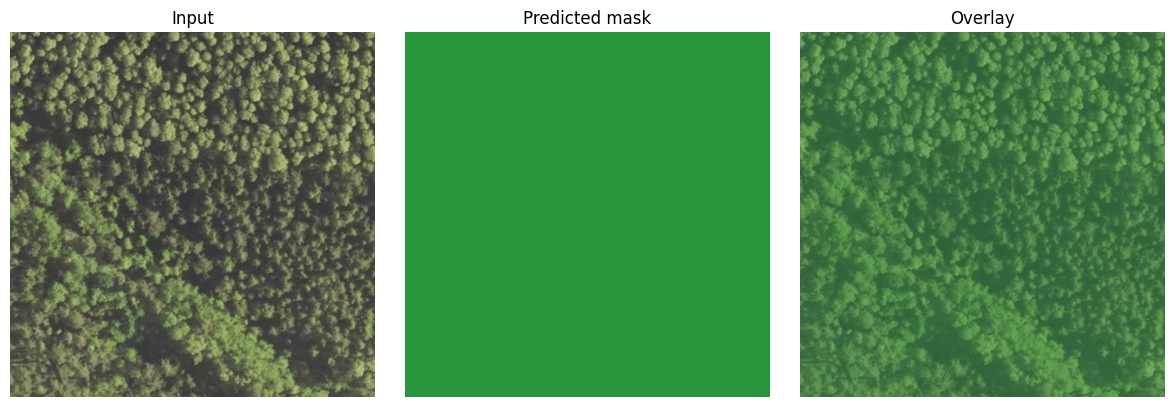

Created: /kaggle/working/demo_package_old_split.zip | 28.8 MB


In [29]:
import sys
import importlib
import matplotlib.pyplot as plt

# README + requirements for whoever builds the demo
with open(f"{DEMO_DIR}/requirements_demo.txt", "w") as f:
    f.write("streamlit\ntorch\nopencv-python-headless\npillow\nnumpy\n")
with open(f"{DEMO_DIR}/README_demo.txt", "w") as f:
    f.write("""Demo package: land-cover segmentation (U-Net trained from scratch on LandCover.ai)

Files
  unet_best.pt          trained weights (best seed by validation mIoU)
  unet_model.py         model architecture (must be next to the weights)
  config.json           class names, colours, image size, normalization
  predict_utils.py      load_model(), predict_mask(), colorize(), overlay(), class_percentages()
  streamlit_app.py      example Streamlit interface

Run (CPU is enough)
  pip install -r requirements_demo.txt
  streamlit run streamlit_app.py

Use in your own code
  from predict_utils import load_model, predict_mask, colorize
  model = load_model()                    # image: uint8 RGB array (H, W, 3)
  mask = predict_mask(model, image)       # (H, W) array of class ids 0..4
  colorize(mask)                          # RGB picture of the mask

Classes: 0 Background, 1 Buildings, 2 Woodlands, 3 Water, 4 Roads
""")

# Test the package exactly like the demo will use it: load the model and predict one real test image
sys.path.insert(0, DEMO_DIR)
import predict_utils
importlib.reload(predict_utils)

demo_model = predict_utils.load_model(device=DEVICE)
test_files = sorted(glob.glob(f"{DATA_ROOT}/test/images/*.jpg"))
demo_img = cv2.cvtColor(cv2.imread(test_files[0]), cv2.COLOR_BGR2RGB)
demo_mask = predict_utils.predict_mask(demo_model, demo_img, device=DEVICE)
print("Demo test OK | image:", demo_img.shape, "| mask:", demo_mask.shape)
print({k: round(v, 1) for k, v in predict_utils.class_percentages(demo_mask).items()})

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, pic, title in zip(ax, [demo_img, predict_utils.colorize(demo_mask), predict_utils.overlay(demo_img, demo_mask)],
                         ["Input", "Predicted mask", "Overlay"]):
    a.imshow(pic)
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig8_demo_example_{RUN_NAME}.png", dpi=150)
plt.show()

# One zip with everything the person who builds the demo needs
zip_path = shutil.make_archive(f"/kaggle/working/demo_package_{RUN_NAME}", "zip", DEMO_DIR)
print("Created:", zip_path, "| %.1f MB" % (os.path.getsize(zip_path) / 1e6))